# Trend-following strategy

This code lays the foundation for a trend-following strategy.

In [3]:
from pathlib import Path
import sys
import matplotlib.pyplot as plt
import numpy as np
import polars as pl

NOTEBOOK_FILE = globals().get("__vsc_ipynb_file__")
WORKSPACE_FOLDER = Path(NOTEBOOK_FILE).resolve().parents[1] if NOTEBOOK_FILE else Path.cwd()
sys.path.insert(0, str(WORKSPACE_FOLDER / "src"))

from backtest.evaluation import calc_key_figures, plot_key_figures

DATE_COL = "AsOfDate"
PRICES = pl.read_csv(WORKSPACE_FOLDER / "prices" / "example_prices.csv", try_parse_dates=True).rename({"dates": DATE_COL})
INSTRUMENTS = [c for c in PRICES.columns if c != DATE_COL]

### Strategy summarized
* Calculate the signal for the last $M$ days:

    $$X_{T, j} = \text{sign}\left(\sum\limits_{k = T - M + 1}^T{r_{k, j}}\right) = \text{sign}(P_{T, j} - P_{T - M, j})$$

    Note that the signal for a given asset will be $\pm 1$ (apart from exact ties).

* Estimate the volatility of the assets at time $T$ from the last $N$ days:
    $$\sigma_{T,j} = \sqrt{\frac{1}{N}\sum_{k=T-N+1}^{T} r_{k,j}^2}$$

* Calculate the positions $\tilde X_{T,j}$ that would make each asset contribute approximately equal risk to the portfolio (ignoring correlations between assets):
    $$\tilde X_{T,j} = \frac{X_{T,j}}{\sigma_{T,j}}$$

* The returns from  these positions need to be calculated taking into account the two-day lag:
    $$R_T = \sum_j \tilde X_{T-2,j}\, r_{T,j}$$

* The next step is to calculate the portfolio risk from holding equally-risk-weighted positions:
    $$\hat\sigma_T = \text{std}\left(R_{T-N+1}, \dots, R_T\right)$$

* We can then calculate the final portfolio positions as:
    $$\hat X_{T,j} = \frac{\tilde X_{T,j}}{\hat\sigma_T}$$

    Dividing by $\sigma_{T,j}$ balances risk between assets, and dividing by $\hat\sigma_T$ keeps the risk of the whole strategy steady over time. Defining the risk of an asset as the size of our position multiplied by its volatility, and using $|X_{T,j}| = 1$:

    $$\text{risk}_{T+2,j} = \sigma^{\text{true}}_{T+2,j} \cdot |\hat X_{T,j}| = \sigma^{\text{true}}_{T+2,j} \cdot \frac{|X_{T,j}|}{\sigma_{T,j}\,\hat\sigma_T} \approx \frac{1}{\hat\sigma_T}$$

    Every asset therefore carries about the same risk, $1/\hat\sigma_T$.

* The realized return from the portfolio will be:

    $$\hat R_{T+2} = \sum_j \hat X_{T,j}\, r_{T+2,j} = \frac{1}{\hat\sigma_T}\sum_j \tilde X_{T,j}\, r_{T+2,j} = \frac{R_{T+2}}{\hat\sigma_T}$$

    Let $\sigma^{\text{true}}_{T+2}$ be the true, unobserved volatility of $R_{T+2}$, given the data through day $T$. Since $\hat\sigma_T$ is known on day $T$, it acts as a constant:

    $$\text{Var}\left(\hat R_{T+2} \mid \text{data through } T\right) = \frac{\text{Var}\left(R_{T+2} \mid \text{data through } T\right)}{\hat\sigma_T^2} = \frac{\left(\sigma^{\text{true}}_{T+2}\right)^2}{\hat\sigma_T^2} \approx 1$$

    The final return therefore has a standard deviation of about 1, provided $\hat\sigma_T$ is a good forecast of $\sigma^{\text{true}}_{T+2}$.

* The trend-following comes from holding the direction of the last $M$ days. We go long if the price has risen and short if it has fallen, so the return on asset $j$ is:

    $$\hat X_{T,j}\, r_{T+2,j} = \frac{\text{sign}(P_{T,j} - P_{T-M,j})\, r_{T+2,j}}{\sigma_{T,j}\,\hat\sigma_T}$$

    This is positive when the return on day $T+2$ has the same sign as the past trend, and negative when it goes against it. The strategy therefore makes money on average if:

    $$E\left[\text{sign}(P_{T,j} - P_{T-M,j})\, r_{T+2,j}\right] > 0$$

    This requires price trends to persist. The autocorrelation analysis in `modeling_example.ipynb` supports this, with positive autocorrelation for blocks of about 20 days or more.

* Trading incurs a transaction cost proportional to the size of each order. As calculated in `evaluation.py`, the net return of the strategy is:

    $$\hat R^{\text{net}}_T = \sum_j \left[\hat X_{T-2,j}\, r_{T,j} - c\, s_{T,j} \left|\hat X_{T-2,j} - \hat X_{T-3,j}\right|\right]$$

    Here $c = 0.02$, and $s_{T,j}$ is the rolling 100-day standard deviation of the daily returns of asset $j$, using data through day $T-1$. This net return is what the Adjusted Sharpe Ratio is evaluated on.

    Costs arise in two ways. The largest orders come from trend reversals, when $X_{T,j}$ flips sign, while smaller orders occur almost every day as $\sigma_{T,j}$ and $\hat\sigma_T$ change. A longer $M$ flips less often and reduces costs, but reacts more slowly to new trends.




In [9]:
def calc_positions(M, prices, N=100):
    """
    Calculate the final positions of the trend-following strategy.

    Parameters:
    M (int): The lookback period of the trend signal, in days.
    prices (pl.DataFrame): DataFrame containing a date column and one price column per instrument.
    N (int): The window for the volatility and portfolio risk estimates, in days.

    Returns:
    pl.DataFrame: The date column and the final position of each instrument. Positions are null
    until there is enough data for both windows.
    """
    instruments = [c for c in prices.columns if c != DATE_COL]
    returns = prices.select(pl.col(instruments).diff())

    # Signal: X_T = sign(P_T - P_{T-M})
    X = prices.select(pl.col(instruments).diff(M).sign())

    # Asset volatility: sigma_T = sqrt(mean of r^2 over the last N days)
    sigma = returns.select(pl.col(instruments).pow(2).rolling_mean(N).sqrt())

    # Equal-risk positions: X_tilde_T = X_T / sigma_T
    X_tilde = X / sigma

    # Portfolio return with the two-day lag: R_T = sum over j of X_tilde_{T-2} * r_T
    asset_returns = X_tilde.select(pl.all().shift(2)) * returns
    R = asset_returns.select(
        pl.when(pl.all_horizontal(pl.all().is_null()))
        .then(None)
        .otherwise(pl.sum_horizontal(pl.all()))
        .alias("R")
    )["R"]

    # Portfolio risk: sigma_hat_T = std of R over the last N days
    sigma_hat = R.rolling_std(N)

    # Final positions: X_hat_T = X_tilde_T / sigma_hat_T
    X_hat = X_tilde.select(pl.all() / sigma_hat).fill_nan(None)

    return X_hat.with_columns(prices[DATE_COL]).select(DATE_COL, *instruments)


positions = calc_positions(50, PRICES)
print(positions)

shape: (5_956, 6)
┌────────────┬───────────┬───────────┬───────────┬───────────┬───────────┐
│ AsOfDate   ┆ diamonds  ┆ butter    ┆ cars      ┆ cucumber  ┆ bananas   │
│ ---        ┆ ---       ┆ ---       ┆ ---       ┆ ---       ┆ ---       │
│ date       ┆ f64       ┆ f64       ┆ f64       ┆ f64       ┆ f64       │
╞════════════╪═══════════╪═══════════╪═══════════╪═══════════╪═══════════╡
│ 2000-01-03 ┆ null      ┆ null      ┆ null      ┆ null      ┆ null      │
│ 2000-01-04 ┆ null      ┆ null      ┆ null      ┆ null      ┆ null      │
│ 2000-01-05 ┆ null      ┆ null      ┆ null      ┆ null      ┆ null      │
│ 2000-01-06 ┆ null      ┆ null      ┆ null      ┆ null      ┆ null      │
│ 2000-01-07 ┆ null      ┆ null      ┆ null      ┆ null      ┆ null      │
│ …          ┆ …         ┆ …         ┆ …         ┆ …         ┆ …         │
│ 2023-01-05 ┆ -0.327562 ┆ -0.235383 ┆ -0.253327 ┆ 0.465459  ┆ -0.10598  │
│ 2023-01-06 ┆ -0.326782 ┆ 0.234714  ┆ -0.25022  ┆ 0.466352  ┆ -0.105565 │
│ 2023-

### Evaluation
We evaluate the positions with the tools in `evaluation.py`, including its approximation of transaction costs (slippage).

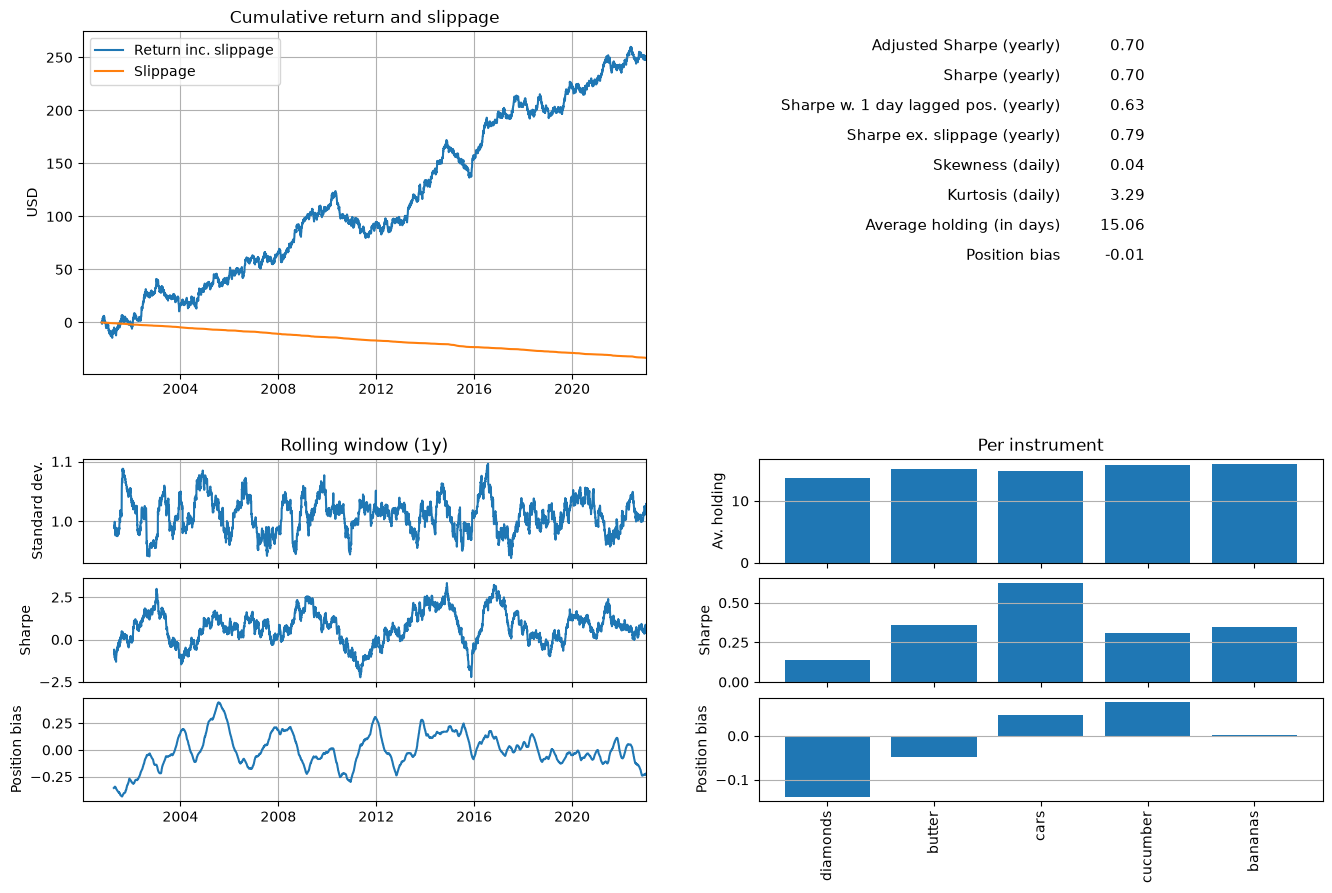

In [10]:
plot_key_figures(positions, PRICES)

#### Key figures
The default key figures as a dict. See the documentation in `evaluation.py` for what each one means.

In [6]:
calc_key_figures(positions, PRICES)

{'sharpe': 0.6970436057632394,
 'sharpe_1d_lag': 0.629792191590981,
 'av_holding': 15.056490889910663,
 'position_bias': -0.012368841381786287,
 'skewness': 0.04237862781809872,
 'kurtosis': 3.2879390057927207,
 'adjusted_sharpe': 0.6964121464782619}

#### Cost sensitivity
How the Sharpe ratio changes with the cost coefficient. The default in `evaluation.py` is `costs=-0.02`.

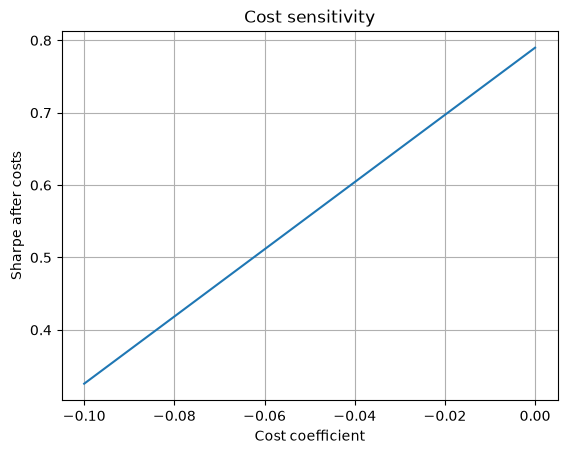

In [7]:
cost_coeffs = np.linspace(0, -0.1, 10)
sharpe_per_cost_coef = [
    calc_key_figures(positions, PRICES, costs=float(cost), key_figures=["sharpe"])["sharpe"]
    for cost in cost_coeffs
]
fig, ax = plt.subplots()
ax.plot(cost_coeffs, sharpe_per_cost_coef)
ax.set_title("Cost sensitivity")
ax.set_ylabel("Sharpe after costs")
ax.set_xlabel("Cost coefficient")
ax.grid()

### Leakage test
Positions on day $T$ may only use data up to and including day $T$. We test this in the two ways described in the instructions: by using a shorter history, and by changing the prices after day $T$. In both cases, the positions up to day $T$ must stay identical.

In [8]:
def check_no_leakage(position_func, prices, days_removed=20):
    """
    Raise an AssertionError if the positions from position_func depend on future data.

    Parameters:
    position_func (callable): Takes a prices DataFrame and returns a positions DataFrame.
    prices (pl.DataFrame): DataFrame containing a date column and one price column per instrument.
    days_removed (int): The number of days to remove in the shorter-history test.
    """
    instruments = [c for c in prices.columns if c != DATE_COL]
    full = position_func(prices)

    # Test 1: positions from a shorter history must equal those from the full history
    truncated = position_func(prices.head(prices.height - days_removed))
    assert truncated.equals(full.head(truncated.height)), "Leakage: shorter history changes earlier positions"

    # Test 2: changing prices after day T must not change positions up to and including day T
    T = prices.height // 2
    is_future = pl.int_range(pl.len()) > T
    altered = prices.with_columns(
        pl.when(is_future).then(pl.col(c) * 1.5 + 100).otherwise(pl.col(c)).alias(c) for c in instruments
    )
    assert position_func(altered).head(T + 1).equals(full.head(T + 1)), "Leakage: future prices change earlier positions"


check_no_leakage(lambda prices: calc_positions(50, prices), PRICES)
print("Leakage tests passed")

Leakage tests passed
